<a href="https://colab.research.google.com/github/kjmobile/lb2/blob/main/13_Neural_Network_XOR_and_Late_Flights_all.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 13. Neural Networks: The XOR Problem and Late Flights

A **neural network** stacks layers of simple units. Each unit takes a weighted sum of its inputs and passes it
through an **activation function**. One layer can only draw a straight boundary; adding a **hidden layer** lets the
network draw curved ones.

We use **Keras**, the model-building interface of Google's **TensorFlow** library (already installed in Colab).

- **Predict (y):** the XOR of two 0/1 inputs first; then `late` (1 = arrived 15 or more minutes late, 0 = on time)
- **From (X):** `x1`, `x2` for XOR; `month`, `dep_hour`, `distance`, `inbound_delay`, `turn_minutes` for flights

Slides: W3.1, neural networks (XOR problem, hidden layer, activation functions, loss functions, optimizers).

> Training starts from random weights. We fix the random seed so the numbers repeat, but on a different computer
> they can differ slightly from the ones printed here.

> **Full version.** This notebook includes the code that draws every figure. The `_simple` version leaves that code out and shows the same figures as pictures.

---
# Part 1. The XOR Problem

XOR ("exclusive or") is 1 when exactly one of two inputs is 1, and 0 when both are 0 or both are 1. It is the
smallest problem that a single straight boundary cannot solve.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

tf.config.experimental.enable_op_determinism()     # same results every run on this computer

X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([0, 1, 1, 0])
pd.DataFrame({'x1': X_xor[:, 0], 'x2': X_xor[:, 1], 'XOR': y_xor})

,x1,x2,XOR
0,0,0,0
1,0,1,1
2,1,0,1
3,1,1,0


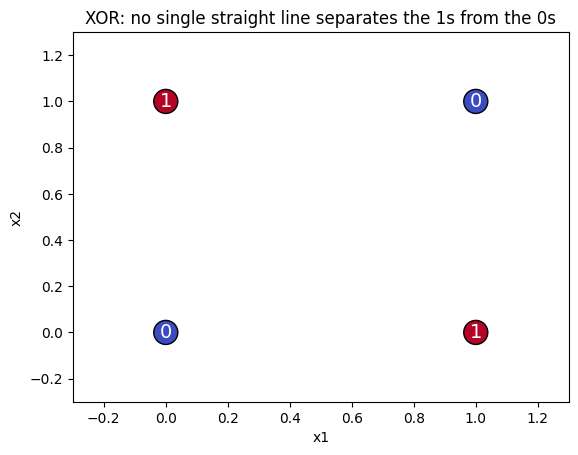

In [2]:
# Figure 1
plt.scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor, cmap='coolwarm', s=300, edgecolors='k')
for (x1, x2), label in zip(X_xor, y_xor):
    plt.annotate(str(label), (x1, x2), ha='center', va='center', color='white', fontsize=14)
plt.xlim(-0.3, 1.3)
plt.ylim(-0.3, 1.3)
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('XOR: no single straight line separates the 1s from the 0s')
plt.show()

## 1. No Hidden Layer: One Straight Line

A network with no hidden layer is one unit: a weighted sum plus a sigmoid, which is logistic regression (notebook 4).

In [3]:
keras.utils.set_random_seed(320)            # same starting weights every run
one_layer = keras.Sequential([
    keras.Input(shape=(2,)),                        # two inputs
    keras.layers.Dense(1, activation='sigmoid')     # one output unit: a probability
])
one_layer.compile(optimizer=keras.optimizers.Adam(learning_rate=0.1), loss='binary_crossentropy', metrics=['accuracy'])
one_layer.fit(X_xor, y_xor, epochs=200, verbose=0)   # 200 passes over the four examples, no printing

print('predictions:', one_layer.predict(X_xor, verbose=0).round(2).ravel())
print('accuracy:', one_layer.evaluate(X_xor, y_xor, verbose=0)[1])

predictions: [0.5 0.5 0.5 0.5]
accuracy: 0.5


The network gives up and says 0.5 for every case. No straight line can put (0,1) and (1,0) on one side and (0,0)
and (1,1) on the other. This is the limit Minsky and Papert pointed out in 1969.

## 2. Add a Hidden Layer

Put 8 units between the inputs and the output. Each uses the **tanh** activation, an S-curve from -1 to 1. The
hidden units bend the space so that one straight line at the end can separate the classes.

In [4]:
keras.utils.set_random_seed(320)
two_layer = keras.Sequential([
    keras.Input(shape=(2,)),
    keras.layers.Dense(8, activation='tanh'),       # hidden layer: 8 units
    keras.layers.Dense(1, activation='sigmoid')     # output
])
two_layer.compile(optimizer=keras.optimizers.Adam(learning_rate=0.1), loss='binary_crossentropy', metrics=['accuracy'])
two_layer.fit(X_xor, y_xor, epochs=200, verbose=0)

print('predictions:', two_layer.predict(X_xor, verbose=0).round(2).ravel())
print('accuracy:', two_layer.evaluate(X_xor, y_xor, verbose=0)[1])

predictions: [0. 1. 1. 0.]


accuracy: 1.0


Solved. The parts of the code:

| Code | Meaning |
|---|---|
| `keras.Sequential([...])` | layers stacked in order |
| `Dense(8, activation='tanh')` | 8 units, each connected to every input |
| `Dense(1, activation='sigmoid')` | output between 0 and 1, read as a probability |
| `loss='binary_crossentropy'` | the loss for yes/no answers: small when the predicted probability of the true answer is high |
| `optimizer=Adam(...)` | how the weights are updated after each pass (a refined gradient descent) |
| `epochs=200` | how many passes over the training data |

In [5]:
print('weights to learn:', two_layer.count_params())    # 2x8 + 8 (hidden) + 8x1 + 1 (output)

weights to learn: 33


---
# Part 2. A Neural Network for Late Flights

> **Data.** 2,000 U.S. domestic flights from 2024, picked at random from the on-time records of the U.S. Bureau of
> Transportation Statistics (BTS), read straight from the course GitHub repository. Source: BTS Marketing Carrier
> On-Time Performance, 2024 (public data).

The five inputs are `month`, `dep_hour`, `distance`, `inbound_delay` (how late the incoming plane arrived) and
`turn_minutes` (scheduled time to turn the plane around); `late` = 1 if the flight arrived 15+ minutes late.

## 3. Data, Split and Scaling

Neural networks train best when inputs are on similar scales, so standardize as in notebook 9.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

flights = pd.read_csv('https://raw.githubusercontent.com/kjmobile/lb2/main/data/flights_late_2024.csv')
X = flights.drop(columns='late')
y = flights['late']
train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.2, random_state=320, stratify=y)

scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_X)
test_scaled = scaler.transform(test_X)
print('train:', train_scaled.shape, ' test:', test_scaled.shape)

train: (1600, 5)  test: (400, 5)


## 4. A Multilayer Perceptron

Two hidden layers (16 and 8 units) with the **ReLU** activation (0 for negative sums, the sum itself otherwise), and a
sigmoid output. `validation_split=0.2` holds out the last 20% of the training flights to watch for overfitting.

In [7]:
keras.utils.set_random_seed(320)
mlp = keras.Sequential([
    keras.Input(shape=(5,)),                        # five inputs
    keras.layers.Dense(16, activation='relu'),      # hidden layer 1
    keras.layers.Dense(8, activation='relu'),       # hidden layer 2
    keras.layers.Dense(1, activation='sigmoid')     # P(late)
])
mlp.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
history = mlp.fit(train_scaled, train_y, epochs=50, batch_size=32, validation_split=0.2, verbose=0)

print('weights to learn:', mlp.count_params())
print('final training loss:  ', round(history.history['loss'][-1], 3))
print('final validation loss:', round(history.history['val_loss'][-1], 3))

weights to learn: 241
final training loss:   0.342
final validation loss: 0.403


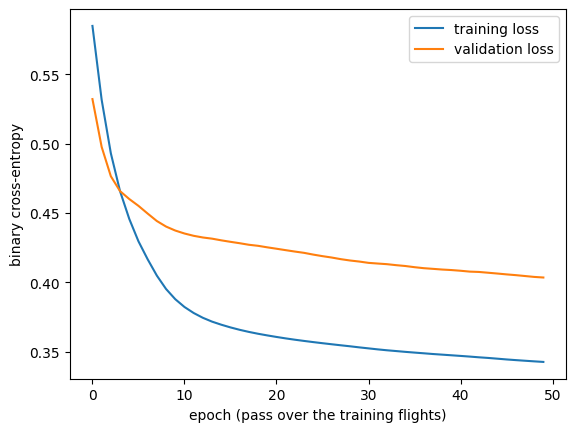

In [8]:
# Figure 2
plt.plot(history.history['loss'], label='training loss')
plt.plot(history.history['val_loss'], label='validation loss')
plt.xlabel('epoch (pass over the training flights)')
plt.ylabel('binary cross-entropy')
plt.legend()
plt.show()

Both losses fall quickly in the first epochs and then level off. If the validation loss started rising while the
training loss kept falling, the network would be overfitting, and we would stop earlier.

## 5. Test, and Compare

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

mlp_accuracy = mlp.evaluate(test_scaled, test_y, verbose=0)[1]
logit = LogisticRegression().fit(train_scaled, train_y)
tree = DecisionTreeClassifier(max_depth=3, random_state=320).fit(train_X, train_y)

print('always guess "on time":', round(1 - test_y.mean(), 3))
print('neural network:        ', round(mlp_accuracy, 3))
print('logistic regression:   ', round(logit.score(test_scaled, test_y), 3))
print('decision tree, depth 3:', round(tree.score(test_X, test_y), 3))

always guess "on time": 0.792
neural network:         0.86
logistic regression:    0.858
decision tree, depth 3: 0.863


The neural network does no better than logistic regression or a three-question tree. With five inputs and 2,000 rows
there is little for the extra layers to find, and the simpler models are far easier to explain. Neural networks pull
ahead when the inputs are many and raw: the pixels of an image, the words of a sentence, a long sequence of
readings. That is where deep learning made its name (next slides: CNNs, RNNs and Transformers).

### Your turn

Use the network on one flight from notebook 6: an evening flight in July (800 miles) with a **50-minute** turn,
whose incoming plane is **40 minutes** late. The tree in notebook 6 said 0.967. What does the network say?

1. In the cell below, fill in the blanks (`___`) and run it. Scale the flight first, as the network was trained on
   scaled inputs.
2. Then finish this sentence:
   *The neural network gives this flight a ___ chance of arriving late.*

<details><summary>Show answer</summary>

```python
flight = pd.DataFrame({'month': [7], 'dep_hour': [18], 'distance': [800],
                       'inbound_delay': [40], 'turn_minutes': [50]})
flight_scaled = scaler.transform(flight)
print('P(late):', mlp.predict(flight_scaled, verbose=0)[0, 0].round(3))
```

*The neural network gives this flight a **0.777** chance of arriving late. It also predicts late, like the tree, but is less sure.*
</details>

In [ ]:
flight = pd.DataFrame({'month': [7], 'dep_hour': [18], 'distance': [800],
                       'inbound_delay': [___], 'turn_minutes': [50]})
flight_scaled = scaler.___(flight)
print('P(late):', mlp.predict(flight_scaled, verbose=0)[0, 0].round(3))

## 6. Summary

| Step | What we found |
|---|---|
| XOR, no hidden layer | Stuck at 0.5 for every case: one straight line cannot separate XOR |
| XOR, one hidden layer | Solved: hidden units bend the space |
| Building blocks | Dense layers, activation (tanh, ReLU, sigmoid), loss (binary cross-entropy), optimizer (Adam), epochs |
| Late flights | About as accurate as logistic regression and a depth-3 tree, and much harder to explain |
| When networks win | Many raw inputs: images, text, sequences |

---
# Challenge

1. In Part 1, change the hidden layer to `Dense(2, activation='tanh')`. Is XOR still solved? Try a few different
   seeds in `keras.utils.set_random_seed(...)`.
2. In Part 2, train for 200 epochs instead of 50 and plot the losses again. Does the validation loss start to rise?
3. Add `keras.layers.Dropout(0.3)` after the first hidden layer (it switches off 30% of the units at random during
   training). Does it change the test accuracy?

In [11]:
# Your answer